In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

np.random.seed(42)

In [2]:
import os
os.environ['WATTTIME_USER'] = 'snigdha_carbon25'
os.environ['WATTTIME_PASSWORD'] = 'SiddU2025!'

from watttime import WattTimeHistorical, WattTimeForecast, WattTimeMyAccess

# regions/signals that can be accessed now
wt_access = WattTimeMyAccess()
print(wt_access.get_access_pandas())

     signal_type       region              region_name       endpoint  \
0       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
1       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
2       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
3       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
4       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
5       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
6  health_damage  CAISO_NORTH  California ISO Northern  v3/historical   
7  health_damage  CAISO_NORTH  California ISO Northern  v3/historical   
8  health_damage  CAISO_NORTH  California ISO Northern    v3/forecast   
9  health_damage  CAISO_NORTH  California ISO Northern    v3/forecast   

        model data_start    data_end train_start  train_end  \
0  2022-10-01 2020-01-01  2024-12-04  2020-03-01 2022-03-01   
1  2023-03-01 2020-03-01  2026-04-02  2021-01-01 2023-03-01   
2  2026

In [4]:
from datetime import datetime, timedelta

wt_hist = WattTimeHistorical()

end = datetime.utcnow()
start = end - timedelta(days=30)

df_watttime = wt_hist.get_historical_pandas(
    region="CAISO_NORTH",
    start=start,
    end=end,
    signal_type="co2_moer"
)
df_watttime.to_csv('../data/grid_carbon_intensity_real.csv', index=False)
df_watttime.head()

/var/folders/pk/l7cr74wn7xlfm6k459rpxw8r0000gn/T/ipykernel_42039/2547013149.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end = datetime.utcnow()


,point_time,value
0,2026-06-24 11:55:00+00:00,1028.7
1,2026-06-24 12:00:00+00:00,988.9
2,2026-06-24 12:05:00+00:00,982.3
3,2026-06-24 12:10:00+00:00,1000.0
4,2026-06-24 12:15:00+00:00,1005.2


In [7]:
from datetime import datetime, timedelta

wt_hist = WattTimeHistorical()

end = datetime.utcnow()
start = end - timedelta(hours=48)

df_watttime = wt_hist.get_historical_pandas(
    region="CAISO_NORTH",
    start=start,
    end=end,
    signal_type="co2_moer"
)

print(len(df_watttime))   
df_watttime               

/var/folders/pk/l7cr74wn7xlfm6k459rpxw8r0000gn/T/ipykernel_42039/202441236.py:5: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  end = datetime.utcnow()


576


,point_time,value
0,2026-07-22 12:05:00+00:00,1014.1
1,2026-07-22 12:10:00+00:00,1010.0
2,2026-07-22 12:15:00+00:00,1010.3
3,2026-07-22 12:20:00+00:00,1015.7
4,2026-07-22 12:25:00+00:00,1019.6
...,...,...
571,2026-07-24 11:40:00+00:00,1001.4
572,2026-07-24 11:45:00+00:00,1001.2
573,2026-07-24 11:50:00+00:00,1026.9
574,2026-07-24 11:55:00+00:00,1003.3


In [8]:
wt_access = WattTimeMyAccess()
access_df = wt_access.get_access_pandas()
print(access_df)

     signal_type       region              region_name       endpoint  \
0       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
1       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
2       co2_moer  CAISO_NORTH  California ISO Northern  v3/historical   
3       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
4       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
5       co2_moer  CAISO_NORTH  California ISO Northern    v3/forecast   
6  health_damage  CAISO_NORTH  California ISO Northern  v3/historical   
7  health_damage  CAISO_NORTH  California ISO Northern  v3/historical   
8  health_damage  CAISO_NORTH  California ISO Northern    v3/forecast   
9  health_damage  CAISO_NORTH  California ISO Northern    v3/forecast   

        model data_start    data_end train_start  train_end  \
0  2022-10-01 2020-01-01  2024-12-04  2020-03-01 2022-03-01   
1  2023-03-01 2020-03-01  2026-04-02  2021-01-01 2023-03-01   
2  2026

In [9]:
wt_forecast = WattTimeForecast()

signal_results = {}
for signal in ['co2_moer', 'health_damage']:
    df_s = wt_forecast.get_forecast_pandas(
        region="CAISO_NORTH",
        signal_type=signal,
        model="2026-03-01"
    )
    print(signal, df_s.columns.tolist())  
    signal_results[signal] = df_s['value'].values[:48]

co2_moer ['point_time', 'value']
health_damage ['point_time', 'value']


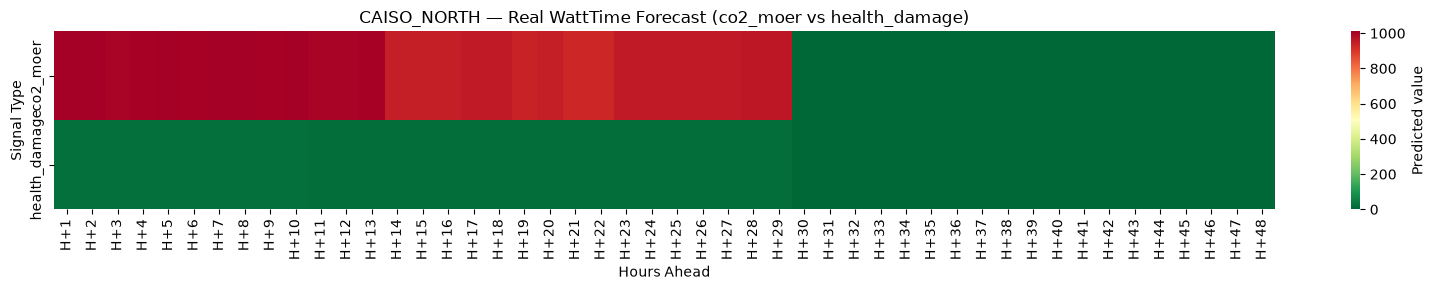

In [10]:
forecast_df = pd.DataFrame(signal_results)
heatmap_data = forecast_df.T
heatmap_data.columns = [f'H+{i+1}' for i in range(heatmap_data.shape[1])]

plt.figure(figsize=(16, 3))
sns.heatmap(heatmap_data, cmap='RdYlGn_r', cbar_kws={'label': 'Predicted value'})
plt.title('CAISO_NORTH — Real WattTime Forecast (co2_moer vs health_damage)')
plt.xlabel('Hours Ahead')
plt.ylabel('Signal Type')
plt.tight_layout()
plt.savefig('../outputs/carbon_heatmap_real.png', dpi=150)
plt.show()

In [11]:
df_hist = wt_hist.get_historical_pandas(
    region="CAISO_NORTH",
    start=start,
    end=end,
    signal_type="co2_moer"
)
print(f"Total samples: {len(df_hist)}")
df_hist.head(10)

2026-07-24 18:45:41,961 [WARNING]  Retrying (Retry(total=2, connect=None, read=None, redirect=None, status=None)) after connection broken by 'ReadTimeoutError("HTTPSConnectionPool(host='api.watttime.org', port=443): Read timed out. (read timeout=60)")': /login


Total samples: 576


,point_time,value
0,2026-07-22 12:05:00+00:00,1014.1
1,2026-07-22 12:10:00+00:00,1010.0
2,2026-07-22 12:15:00+00:00,1010.3
3,2026-07-22 12:20:00+00:00,1015.7
4,2026-07-22 12:25:00+00:00,1019.6
5,2026-07-22 12:30:00+00:00,1017.7
6,2026-07-22 12:35:00+00:00,1022.6
7,2026-07-22 12:40:00+00:00,1022.8
8,2026-07-22 12:45:00+00:00,1020.6
9,2026-07-22 12:50:00+00:00,1019.8
